# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:** Eric Alejandro Moro Rebollo

* **Matrícula:** A01840718

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
DIR = "/content/drive/MyDrive/Colab Notebooks/MNA Maestria en Inteligencia Artificial/MNA-IA y Aprendizaje Automatico TC4058.10/Semana 5"
os.chdir(DIR)

In [4]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [5]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target])
y = df[target]

In [6]:
# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.

smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

X_res, y_res = smote.fit_resample(X, y) # Balanceamos las clases con valores predeterminados de SMOTE.

X_train, X_test, y_train, y_test = train_test_split(
    X_res,
    y_res,
    test_size=0.30,  # Usemos una partición 70%-30%, pero podría ajustarse, en dado caso.
    random_state=RANDOM_STATE  # semilla
)

# **Parte 1. Propuesta original del Analista Junior**

# **Configuración y Entrenamiento de los Modelos**

In [7]:
# --- Modelo 1: Árbol de decisión ---
dt = DecisionTreeClassifier(random_state=RANDOM_STATE  # semilla
                            )
dt.fit(X_train, y_train)

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(random_state=RANDOM_STATE  # semilla
                            )
rf.fit(X_train, y_train)

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(eval_metric='logloss',   # métrica caso binario
                    random_state=RANDOM_STATE  # semilla
                    )
xgb.fit(X_train, y_train)


# Obtenemos los desempeños, verificando que no estén sobreentrenados,
# ni subentrenados:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardemos las probabilidades para uso posterior:
               # 0:DT, 1:RF, 2:XGBoost
print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():

    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)
    y_probs.append(modelo.predict_proba(X_test)[:,1])

    # Verificando en los conjuntos de Train y Test:
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    print(f"{nombre}:")

    print(f"Train: {acc_train:.4f}")
    print(f"Test: {acc_test:.4f}")
    print("+"*20)

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
Random Forest:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
XGBoost:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++


# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [8]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias = dt.feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print(df_importancias)

                Característica:  Importancia
11  dias_max_atraso_30d_despues          1.0
1               ingreso_mensual          0.0
2      antiguedad_laboral_meses          0.0
3              score_crediticio          0.0
0                          edad          0.0
4           utilizacion_credito          0.0
5                   atrasos_12m          0.0
7                 num_productos          0.0
6             consultas_buro_6m          0.0
8                limite_credito          0.0
9                   deuda_total          0.0
10       relacion_deuda_ingreso          0.0
12              cliente_premium          0.0


In [9]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                       Variable  Importancia
11  dias_max_atraso_30d_despues     0.822857
4           utilizacion_credito     0.058264
3              score_crediticio     0.025473
10       relacion_deuda_ingreso     0.023019
6             consultas_buro_6m     0.018116
12              cliente_premium     0.011584
7                 num_productos     0.008276
9                   deuda_total     0.007900
2      antiguedad_laboral_meses     0.006443
0                          edad     0.005921


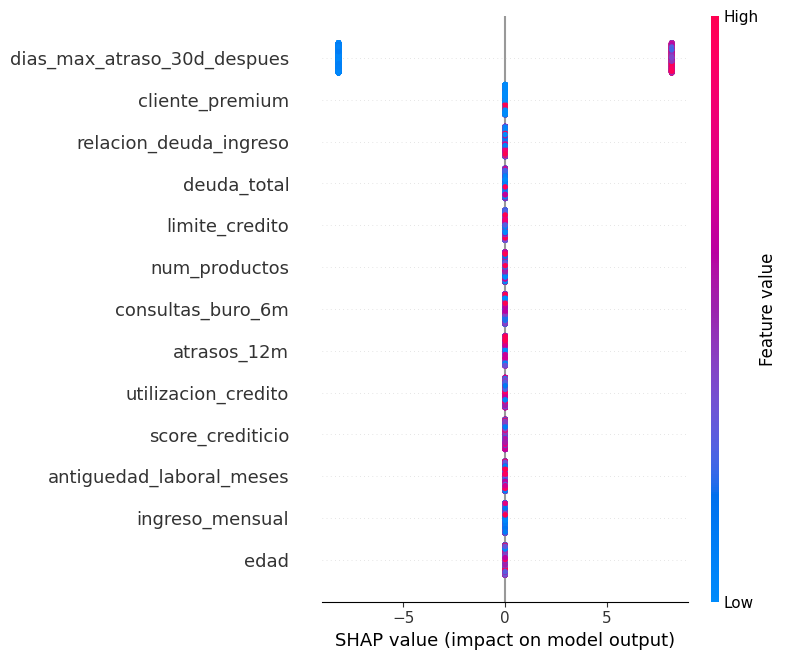

In [10]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)

## **Seleccionemos y analicemos un cliente en Particular:**

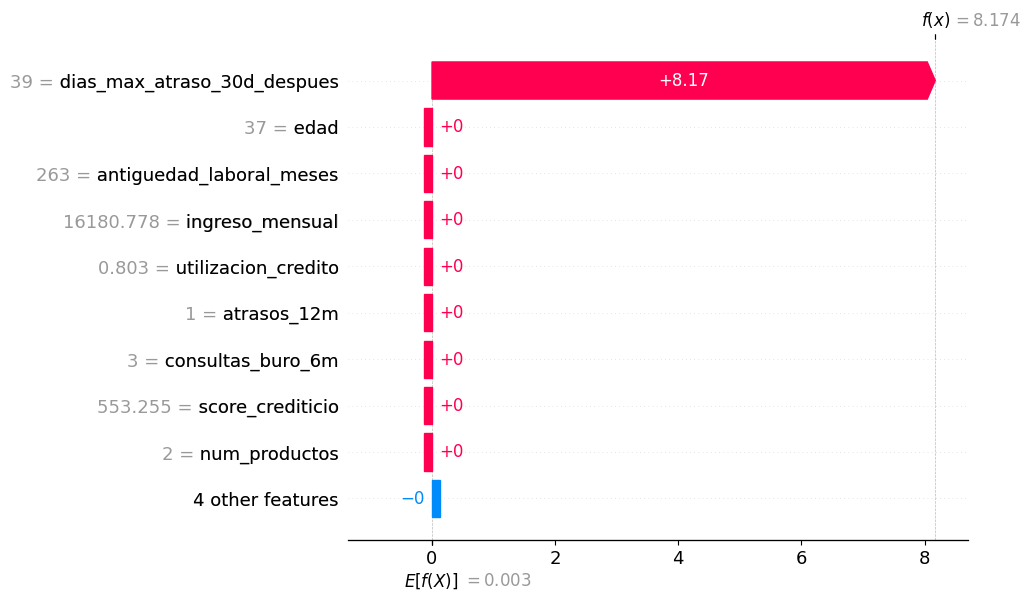

In [11]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_test.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

# **Análisis desde la perspectiva del negocio:**

In [12]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500


In [13]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = y_probs[2]   # XGBoost

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
132700


Mejor umbral: 0.01
Mayor Utilidad (USD): 132700


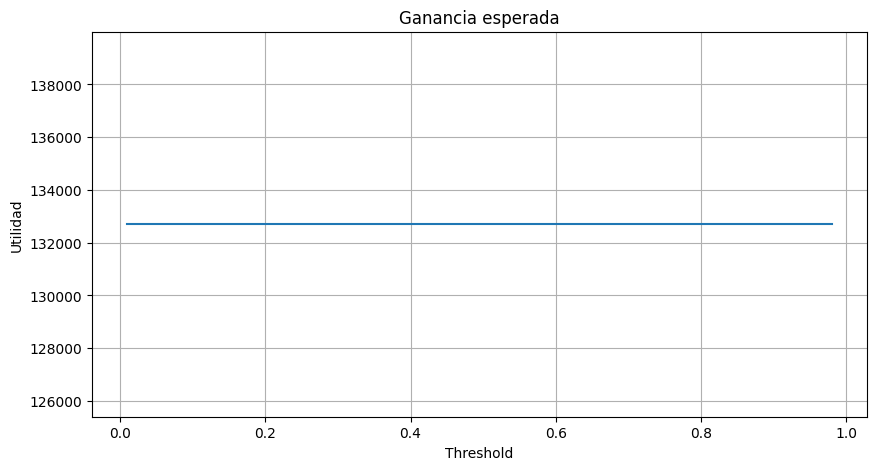

In [14]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_test,
        y_probs_mejor_modelo,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [15]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [16]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $500,944
Threshold óptimo : $500,944
Diferencia : $0
Incremento : 0.0%


## **Matriz de Confusión**



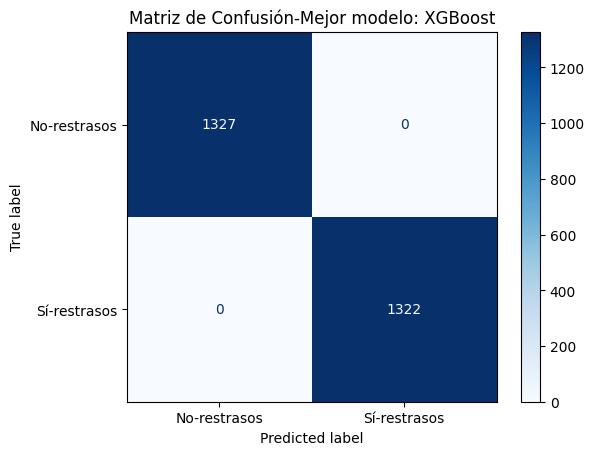

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-restrasos", "Sí-restrasos"]
y_pred = modelo.predict(X_test)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión-Mejor modelo: {nombre}")
plt.show()

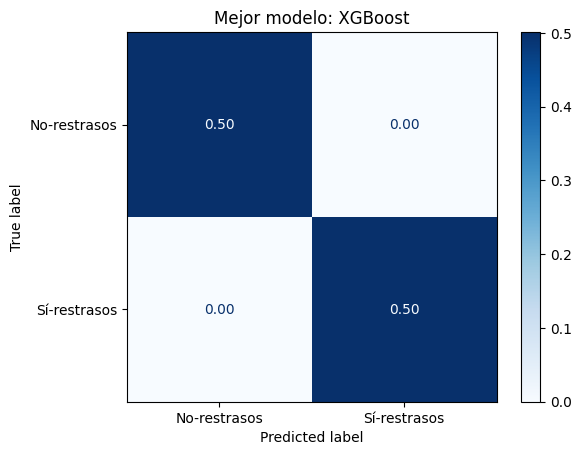

In [18]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"Mejor modelo: {nombre}")
plt.show()

# **Parte 2. Auditoría forense: errores detectados en la propuesta original**

* **E1. Fuga de información por una variable del futuro (el error más grave).** `dias_max_atraso_30d_despues` mide el atraso en los 30 días **posteriores** a la evaluación, información que no existe cuando se decide aprobar el crédito. La propia *Tabla de Variables* lo confirma: la define como el máximo atraso observado en los 30 días posteriores a la fecha de evaluación. Además está casi construida con la misma lógica que la etiqueta: ningún cliente cumplido supera 9 días y ningún moroso tiene menos de 15, así que una sola regla ("si atraso ≥ 15, incumple") acierta el 100%. Los modelos no aprendieron a predecir el riesgo, aprendieron a leer el resultado. En producción esa columna estaría vacía y el desempeño real sería muy inferior al reportado. Es el caso típico de *target leakage* que describe Kaufman et al. (2012).

* **E2. SMOTE aplicado antes de partir los datos.** El balanceo se hizo sobre todos los datos y luego se separó train/test. Cada cliente sintético se crea interpolando entre vecinos reales, así que el conjunto de prueba contiene clientes inventados a partir de registros que también están en el entrenamiento: el modelo se evalúa con información que ya "vio". El rebalanceo debe aplicarse solo al entrenamiento y, si se usa validación cruzada, dentro de cada partición (Géron, 2022; Lemaître et al., 2017).

* **E3. El conjunto de prueba no representa la realidad.** Por el mismo motivo, el "test" tiene ~50% de incumplimientos cuando en la cartera real son 11.7%. Todo lo que se calcula sobre él, incluida la utilidad, describe una población que no existe.

* **E4. Métrica inadecuada (exactitud).** Con 88% de clientes cumplidos, un modelo que aprobara a todos tendría 88% de exactitud sin detectar un solo moroso. La exactitud no distingue entre rechazar a un buen cliente (se pierden \$100) y aprobar a uno que no paga (se pierden \$500). Conviene usar la PR-AUC (área bajo la curva precisión-sensibilidad), ROC-AUC, sensibilidad sobre la clase de incumplimiento y, sobre todo, la utilidad económica (Saito y Rehmsmeier, 2015).

* **E5. Sin conjunto de validación ni validación cruzada, y con hiperparámetros por defecto.** El árbol de decisión sin `max_depth` crece hasta memorizar el entrenamiento (exactitud de 1.0 en train). El buen resultado en "test" no lo detecta porque la fuga lo tapa. Sin la fuga, el mismo árbol obtiene una PR-AUC de 1.000 en entrenamiento y de apenas 0.185 en validación: sobreentrenamiento claro.

* **E6. El umbral se optimizó en el conjunto de prueba.** Se probaron 98 umbrales sobre `X_test` y se reportó el mejor. Eso convierte al test en un conjunto de ajuste y la utilidad reportada queda inflada. El umbral debe elegirse en validación y el test usarse una sola vez al final. La propia salida del cuaderno muestra que algo no cuadra: el "umbral óptimo" sale en 0.01 y la mejora contra 0.5 es de 0%. Con la fuga, las probabilidades son prácticamente 0 o 1 y cualquier umbral da el mismo resultado.

* **E7. La utilidad por 10,000 solicitudes está mal escalada.** Se escala con la proporción de incumplimiento del test balanceado (~50%) y con clientes sintéticos, así que la cifra no corresponde a 10,000 solicitudes reales. Además, no se compara contra la referencia más simple: aprobar a todos sin modelo.

* **E8. Errores en la interpretación SHAP.** (a) El cliente que se explica, `X_test.iloc[11]`, es uno de los registros inventados por SMOTE, no un cliente real. (b) El "factor de riesgo principal" es justamente la variable con fuga. (c) Se mezclan escalas: $f(x)=8.174$ está en *log-odds*, y el umbral de 0.5 es una probabilidad; el equivalente en log-odds de 0.5 es 0, no 0.5 (Lundberg y Lee, 2017).

* **E9. Errores de código en la matriz de confusión.** Usa las variables `modelo` y `nombre` que quedaron de la última vuelta del ciclo; coincide con XGBoost por casualidad, no por diseño. Además, usa `predict()`, es decir, el umbral de 0.5, y no el umbral que el propio análisis declara óptimo.

* **E10. Importancias poco confiables y variable redundante.** `feature_importances_` (por impureza) favorece variables continuas con muchos puntos de corte y se calculó sobre datos sintéticos. Además, `relacion_deuda_ingreso` es exactamente `deuda_total / ingreso_mensual`, así que su importancia se reparte de forma arbitraria entre las tres. No es fuga, pero hay que tenerlo presente al interpretar.

* **E12. Revisión del resto de las variables contra la *Tabla de Variables*.** Ninguna otra variable está definida después de la evaluación: `deuda_total` se mide expresamente "al momento de la evaluación", y `atrasos_12m` y `consultas_buro_6m` miran hacia atrás (12 y 6 meses). Aun así, antes de producción hay que confirmar con las áreas que generaron los datos que cada valor se extrajo *a la fecha de evaluación* y no a la fecha de corte de la base. Esto aplica sobre todo a `score_crediticio`, que se recalcula con el historial acumulado y, si se tomó tarde, ya reflejaría los atrasos que queremos predecir, y a `cliente_premium`, cuya tabla no indica cuándo se asigna el segmento. En estos datos `cliente_premium` casi no se relaciona con el incumplimiento (11.6% contra 12.1%), así que no altera los resultados, pero el riesgo metodológico es el mismo.

* **E11. Umbral de clasificación sin sentido económico.** Con utilidad de \$100 y pérdida de \$500, conviene aprobar solo si $(1-p)\cdot 100 - p \cdot 500 > 0$, es decir, si $p < 1/6 \approx 0.167$ (Elkan, 2001). El umbral de 0.5 no tiene sentido para este negocio, y si las probabilidades se deforman con SMOTE, ese cálculo deja de ser válido.

In [19]:
# ===================== EVIDENCIA DE LOS ERRORES DETECTADOS =====================

# (E1) Fuga de información por una variable del futuro:
print("Días máximos de atraso en los 30 días DESPUÉS de la evaluación, por clase:")
print(df.groupby(target)['dias_max_atraso_30d_despues'].agg(['min', 'max', 'mean']).round(1))
regla = (df['dias_max_atraso_30d_despues'] >= 15).astype(int)
print("\nExactitud de una sola regla 'si atraso >= 15 días -> incumplimiento':", accuracy_score(y, regla))

# (E2) SMOTE aplicado antes de partir los datos: SMOTE agrega los registros sintéticos al final,
# así que cualquier índice >= len(X) es un cliente inventado.
sinteticos_test = X_test.index >= len(X)
print("\nRegistros sintéticos dentro del conjunto de prueba: %d de %d (%.1f%%)"
      % (sinteticos_test.sum(), len(X_test), 100 * sinteticos_test.mean()))
print("Proporción de incumplimiento real en los datos: %.1f%%" % (100 * y.mean()))
print("Proporción de incumplimiento en el 'test' del analista: %.1f%%" % (100 * y_test.mean()))

# (E8) El cliente que se interpreta con SHAP, ¿es real o sintético?
print("\n¿El cliente X_test.iloc[11] es sintético?:", bool(X_test.index[11] >= len(X)))

# (E10) Relación deuda/ingreso es una combinación exacta de otras dos variables:
dif = (df['deuda_total'] / df['ingreso_mensual'] - df['relacion_deuda_ingreso']).abs().max()
print("\nDiferencia máxima entre deuda_total/ingreso_mensual y relacion_deuda_ingreso: %.4f" % dif)

Días máximos de atraso en los 30 días DESPUÉS de la evaluación, por clase:
             min  max  mean
default_90d                
0              0    9   4.5
1             15   89  52.5

Exactitud de una sola regla 'si atraso >= 15 días -> incumplimiento': 1.0

Registros sintéticos dentro del conjunto de prueba: 1162 de 2649 (43.9%)
Proporción de incumplimiento real en los datos: 11.7%
Proporción de incumplimiento en el 'test' del analista: 49.9%

¿El cliente X_test.iloc[11] es sintético?: True

Diferencia máxima entre deuda_total/ingreso_mensual y relacion_deuda_ingreso: 0.0008


# **Parte 3. Propuesta corregida**

Cada corrección responde a uno o más errores de la auditoría:

| Corrección | Errores que atiende | Por qué |
|---|---|---|
| **C1.** Eliminar `dias_max_atraso_30d_despues` | E1, E8 | Es información del futuro; en producción no existe. |
| **C2.** Partir primero, con datos reales y estratificados: 60% entrenamiento, 20% validación, 20% prueba | E2, E3, E5, E6 | Ningún dato de validación o prueba participa en el ajuste, y todos los conjuntos conservan el 11.7% real de incumplimiento. |
| **C3.** Hiperparámetros con validación cruzada estratificada de 5 particiones en entrenamiento, optimizando PR-AUC; sin SMOTE | E2, E4, E5, E11 | Controla la complejidad de cada árbol y mantiene probabilidades realistas para fijar el umbral con criterio económico. Si se quisiera rebalancear, tendría que hacerse dentro de cada partición con un `Pipeline` de imbalanced-learn. |
| **C4.** Función de utilidad vectorizada, escalada con la proporción real y comparada contra "aprobar a todos" | E7, E11 | La cifra por 10,000 solicitudes debe describir clientes reales y compararse con la alternativa de no usar modelo. |
| **C5.** Comparación de train contra validación y elección del modelo y del umbral **en validación** | E4, E5, E6 | Detecta el sub y el sobreentrenamiento y evita usar la prueba para decidir. |
| **C6.** Evaluación única en prueba, intervalos de confianza y matrices de confusión a 0.5 y al umbral elegido | E6, E9 | Da una estimación honesta y mide qué tan incierta es. |
| **C7.** Importancia por permutación, SHAP y dirección del efecto con clientes reales | E8, E10 | Interpretación sin datos sintéticos ni sesgo hacia variables continuas. |

In [20]:
# ===================== PROPUESTA CORREGIDA =====================
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

# C1) Se elimina la variable con información del futuro (fuga de información).
VARS_FUGA = ['dias_max_atraso_30d_despues']
Xc = df.drop(columns=[target] + VARS_FUGA)
yc = df[target]

# C2) Se parte PRIMERO, con los datos reales y de forma estratificada: 60% train, 20% validación, 20% prueba.
#     El conjunto de prueba no se toca hasta el final.
Xtv, Xte, ytv, yte = train_test_split(Xc, yc, test_size=0.20, stratify=yc, random_state=RANDOM_STATE)
Xtr, Xva, ytr, yva = train_test_split(Xtv, ytv, test_size=0.25, stratify=ytv, random_state=RANDOM_STATE)

for nom, yy in [('Train', ytr), ('Validación', yva), ('Prueba', yte)]:
    print(f"{nom:>10}: {len(yy):>5} registros | incumplimiento = {100*yy.mean():.1f}%")

     Train:  3000 registros | incumplimiento = 11.7%
Validación:  1000 registros | incumplimiento = 11.7%
    Prueba:  1000 registros | incumplimiento = 11.7%


### **Justificación de las métricas**

* **Exactitud:** se descarta como métrica principal (E4). Con 11.7% de incumplimiento, aprobar a todos ya da 88.3%.
* **PR-AUC (*average precision*):** es la métrica para ajustar hiperparámetros. Mide qué tan bien el modelo pone a los morosos arriba de la lista y se concentra en la clase minoritaria, que es la que cuesta dinero. Su referencia de azar es la tasa de incumplimiento (0.117), no 0.5, lo que la hace más exigente que la ROC-AUC cuando las clases están desbalanceadas (Saito y Rehmsmeier, 2015).
* **ROC-AUC:** se reporta como complemento, porque es la métrica que más se usa en riesgo crediticio para comparar con otros modelos.
* **Sensibilidad (*recall*) al umbral 0.5:** muestra qué porcentaje de morosos detecta el modelo si nadie ajusta el umbral.
* **Utilidad económica:** es la métrica de decisión final, porque es lo que pidió el negocio. Las otras métricas no saben que un moroso cuesta cinco veces lo que deja un buen cliente.

In [21]:
# C3) Ajuste de hiperparámetros con validación cruzada estratificada SOLO sobre el entrenamiento.
#     Métrica: average_precision (área bajo la curva Precisión-Sensibilidad), adecuada con clases desbalanceadas.
#     No se rebalancea con SMOTE ni con pesos: queremos probabilidades realistas para fijar después
#     el umbral con criterio económico.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

busquedas = {
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'max_depth': [3, 4, 5, 6, 8], 'min_samples_leaf': [10, 20, 50]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {'max_depth': [4, 6, 8], 'min_samples_leaf': [5, 10, 20], 'max_features': ['sqrt', 0.5]}),
    "XGBoost": (
        XGBClassifier(eval_metric='logloss', subsample=0.8, colsample_bytree=0.8,
                      random_state=RANDOM_STATE, n_jobs=-1),
        {'max_depth': [2, 3, 4], 'learning_rate': [0.03, 0.1], 'n_estimators': [200, 400],
         'min_child_weight': [1, 5]}),
}

modelos_c = {}
cv_prauc = {}
for nombre, (modelo, grid) in busquedas.items():
    gs = GridSearchCV(modelo, grid, scoring='average_precision', cv=cv, n_jobs=-1)
    gs.fit(Xtr, ytr)
    modelos_c[nombre] = gs.best_estimator_
    cv_prauc[nombre] = gs.best_score_
    print(f"{nombre}: mejores hiperparámetros {gs.best_params_} | PR-AUC (CV) = {gs.best_score_:.3f}")

Árbol de Decisión: mejores hiperparámetros {'max_depth': 4, 'min_samples_leaf': 20} | PR-AUC (CV) = 0.328
Random Forest: mejores hiperparámetros {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 20} | PR-AUC (CV) = 0.403
XGBoost: mejores hiperparámetros {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 200} | PR-AUC (CV) = 0.425


In [22]:
# C4) Funciones de negocio (vectorizadas). Regla: se APRUEBA el crédito si P(incumplimiento) < umbral.
def utilidad_c(y_true, y_prob, umbral):
    y_true = np.asarray(y_true); aprobar = np.asarray(y_prob) < umbral
    return GANANCIA_BUENO * np.sum(aprobar & (y_true == 0)) + PERDIDA_DEFAULT * np.sum(aprobar & (y_true == 1))

def utilidad_10k(y_true, y_prob, umbral):
    return utilidad_c(y_true, y_prob, umbral) * 10_000 / len(y_true)

UMBRALES = np.round(np.arange(0.01, 0.99, 0.01), 2)

# Referencia de negocio: aprobar a todos (sin modelo) y umbral teórico de equilibrio.
print("Utilidad por 10,000 solicitudes si se aprueba a TODOS (validación): $%s"
      % f"{utilidad_10k(yva, np.zeros(len(yva)), 0.5):,.0f}")
print("Umbral de equilibrio teórico: aprobar si p < 100/(100+500) = %.3f" % (100 / 600))

Utilidad por 10,000 solicitudes si se aprueba a TODOS (validación): $298,000
Umbral de equilibrio teórico: aprobar si p < 100/(100+500) = 0.167


In [23]:
# C5) Comparación de los 3 modelos: train vs validación (sub/sobreentrenamiento) y criterio económico.
filas = []
probs_va = {}
for nombre, m in modelos_c.items():
    p_tr = m.predict_proba(Xtr)[:, 1]
    p_va = m.predict_proba(Xva)[:, 1]
    probs_va[nombre] = p_va
    u = [utilidad_c(yva, p_va, t) for t in UMBRALES]
    t_opt = UMBRALES[int(np.argmax(u))]
    filas.append({
        'modelo': nombre,
        'PR-AUC CV (train)': cv_prauc[nombre],
        'PR-AUC train': average_precision_score(ytr, p_tr),
        'PR-AUC val': average_precision_score(yva, p_va),
        'ROC-AUC train': roc_auc_score(ytr, p_tr),
        'ROC-AUC val': roc_auc_score(yva, p_va),
        'Recall val (0.5)': recall_score(yva, (p_va >= 0.5).astype(int)),
        'Utilidad/10k val (0.5)': utilidad_10k(yva, p_va, 0.5),
        'Umbral óptimo (val)': t_opt,
        'Utilidad/10k val (óptimo)': utilidad_10k(yva, p_va, t_opt),
    })
comparacion = pd.DataFrame(filas).set_index('modelo')
comparacion['Brecha PR-AUC'] = comparacion['PR-AUC train'] - comparacion['PR-AUC val']
pd.set_option('display.width', 250)
print(comparacion.round(3).T)

# Selección (solo con información de entrenamiento y validación):
# 1) Se consideran empatados los modelos cuya utilidad en validación está a menos de 2% de la mejor.
#    Con ~117 morosos en validación, 2% equivale a uno o dos clientes: es ruido, no una diferencia real.
# 2) Entre los empatados se elige el de mayor PR-AUC en validación cruzada, la estimación más estable
#    de qué tan bien ordena el riesgo.
TOLERANCIA = 0.02
u_val = comparacion['Utilidad/10k val (óptimo)']
candidatos = comparacion[u_val >= u_val.max() * (1 - TOLERANCIA)]
mejor_nombre = candidatos['PR-AUC CV (train)'].idxmax()
print("Modelos empatados en utilidad (diferencia < 2%):", list(candidatos.index))
mejor_m = modelos_c[mejor_nombre]
mejor_umbral = comparacion.loc[mejor_nombre, 'Umbral óptimo (val)']
print(f"\nModelo seleccionado: {mejor_nombre} | umbral elegido en validación: {mejor_umbral:.2f}")

modelo                     Árbol de Decisión  Random Forest     XGBoost
PR-AUC CV (train)                      0.328          0.403       0.425
PR-AUC train                           0.420          0.550       0.512
PR-AUC val                             0.447          0.516       0.530
ROC-AUC train                          0.797          0.871       0.850
ROC-AUC val                            0.831          0.848       0.853
Recall val (0.5)                       0.265          0.034       0.154
Utilidad/10k val (0.5)            432000.000     317000.000  383000.000
Umbral óptimo (val)                    0.130          0.210       0.150
Utilidad/10k val (óptimo)         561000.000     574000.000  569000.000
Brecha PR-AUC                         -0.028          0.033      -0.018
Modelos empatados en utilidad (diferencia < 2%): ['Random Forest', 'XGBoost']

Modelo seleccionado: XGBoost | umbral elegido en validación: 0.15


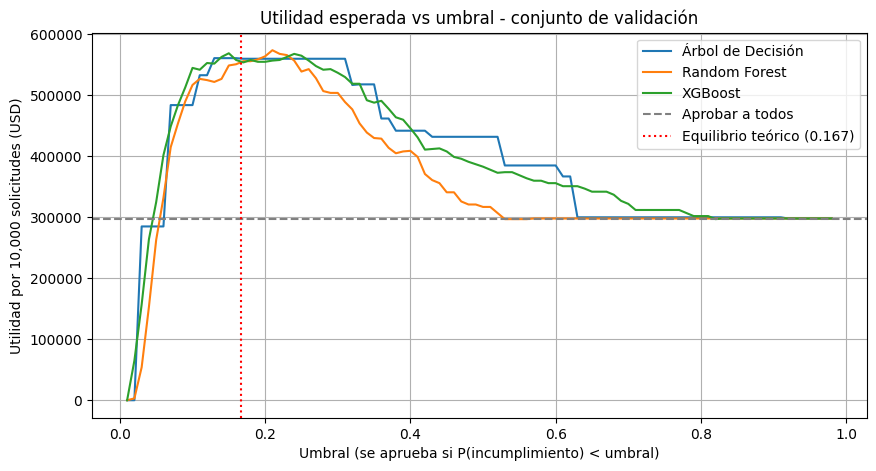

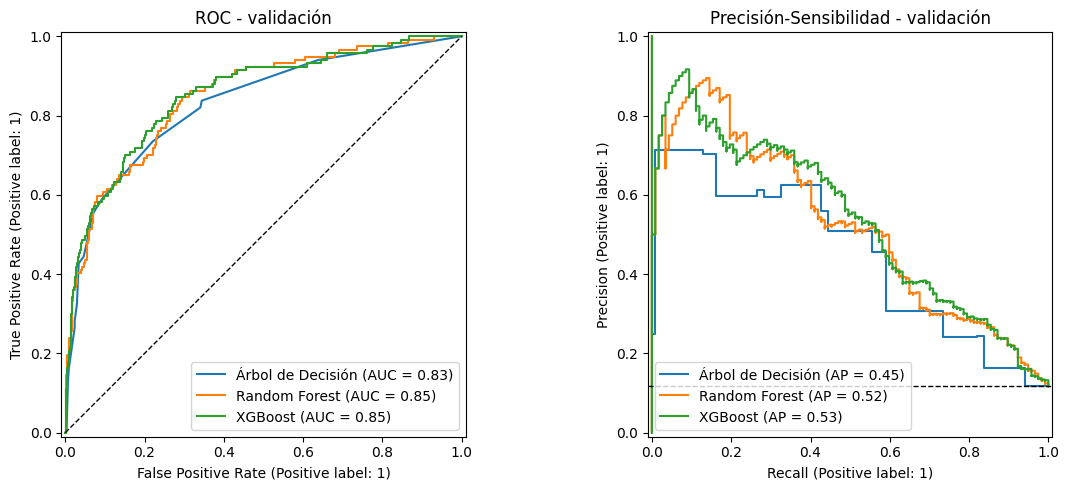

In [24]:
# Curva de utilidad vs umbral en VALIDACIÓN para los tres modelos:
plt.figure(figsize=(10, 5))
for nombre, p_va in probs_va.items():
    plt.plot(UMBRALES, [utilidad_10k(yva, p_va, t) for t in UMBRALES], label=nombre)
plt.axhline(utilidad_10k(yva, np.zeros(len(yva)), 0.5), color='gray', ls='--', label='Aprobar a todos')
plt.axvline(100/600, color='red', ls=':', label='Equilibrio teórico (0.167)')
plt.xlabel('Umbral (se aprueba si P(incumplimiento) < umbral)')
plt.ylabel('Utilidad por 10,000 solicitudes (USD)')
plt.title('Utilidad esperada vs umbral - conjunto de validación')
plt.legend(); plt.grid(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for nombre, m in modelos_c.items():
    RocCurveDisplay.from_estimator(m, Xva, yva, name=nombre, ax=ax[0])
    PrecisionRecallDisplay.from_estimator(m, Xva, yva, name=nombre, ax=ax[1])
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_title('ROC - validación')
ax[1].axhline(yva.mean(), color='k', ls='--', lw=1, label='Azar'); ax[1].set_title('Precisión-Sensibilidad - validación')
plt.tight_layout(); plt.show()

### **Comparación de los modelos (Evaluación)**

La tabla C5 y las curvas permiten comparar a los tres modelos con las mismas reglas. Estas son las diferencias que observé:

* **Capacidad para ordenar el riesgo.** El árbol de decisión, limitado a pocos niveles, llega a una PR-AUC de 0.447 y una ROC-AUC de 0.831 en validación. Random Forest sube a 0.516 y 0.848, y XGBoost a 0.530 y 0.853. Los modelos de ensamble capturan combinaciones de factores (por ejemplo, alta utilización *y* muchas consultas al buró) que un solo árbol poco profundo no alcanza a representar.
* **El umbral de 0.5 casi no sirve.** Con una tasa de incumplimiento de 11.7%, muy pocos clientes superan 50% de probabilidad. Por eso, con 0.5, Random Forest detecta apenas el 3.4% de los morosos y XGBoost el 15.4%, y sus utilidades quedan cerca de la de aprobar a todos. El árbol detecta más (26.5%) porque sus hojas producen probabilidades más extremas, no porque ordene mejor.
* **Con umbral económico, los tres quedan cerca.** Al optimizar el umbral en validación, los umbrales caen entre 0.13 y 0.21, alrededor del equilibrio teórico de 0.167. Eso indica que las probabilidades son razonables, gracias a que no se usó SMOTE. Por cada 10,000 solicitudes, la utilidad es de \$561,000 con el árbol, \$574,000 con Random Forest y \$569,000 con XGBoost: a lo mucho \$13,000 de diferencia entre los tres. La lección es que corregir los datos y el umbral pesa mucho más que la elección del algoritmo.
* **Selección: XGBoost.** Random Forest tiene la utilidad más alta en validación, pero solo por \$5,000 por cada 10,000 solicitudes. Sobre los 1,000 clientes de validación eso equivale a un solo moroso, una diferencia que puede cambiar con otra muestra. Por eso la regla de C5 considera empatados a los modelos que están a menos de 2% del mejor y desempata con la PR-AUC de validación cruzada. Con información exclusivamente de entrenamiento y validación, XGBoost es superior en todo lo demás:
  * Mejor PR-AUC en validación cruzada (0.425 contra 0.403).
  * Mejor PR-AUC y ROC-AUC en validación (0.530 y 0.853).
  * Sin sobreentrenamiento: su brecha es de -0.018, contra 0.033 de Random Forest.
  * Con `max_depth=2` y `learning_rate=0.03` es, además, un modelo más sencillo que un bosque de 300 árboles de profundidad 6.

  La tabla informativa de prueba (C6b) apunta en la misma dirección, pero no se usó para decidir.

Modelo: XGBoost
PR-AUC prueba: 0.393 | ROC-AUC prueba: 0.804

Utilidad por cada 10,000 solicitudes (prueba):
  Aprobar a todos (sin modelo): $298,000
  Modelo con umbral 0.50:       $366,000
  Modelo con umbral 0.15:       $532,000
  Mejora del umbral óptimo vs 0.50:  $166,000
  Mejora del modelo vs aprobar a todos: $234,000

Umbral 0.50: se rechaza al 2.8% de solicitantes | incumplimientos detectados 16/117 | buenos clientes rechazados 12/883

Umbral 0.15: se rechaza al 24.0% de solicitantes | incumplimientos detectados 79/117 | buenos clientes rechazados 161/883


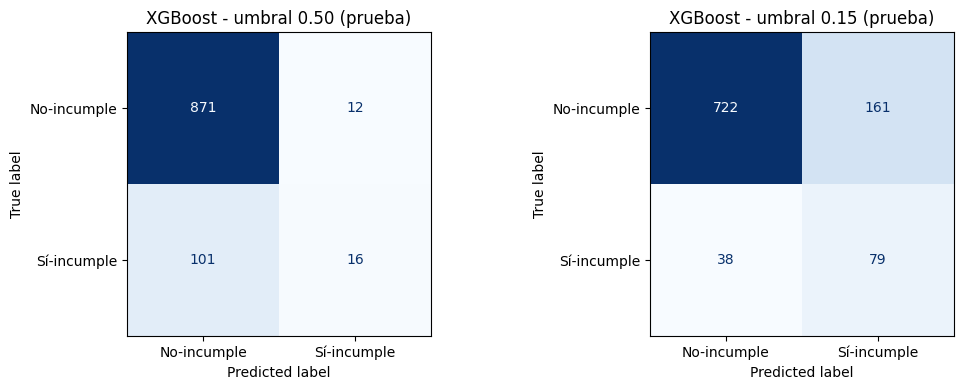

In [25]:
# C6) Evaluación FINAL, una sola vez, en el conjunto de prueba (datos reales, nunca usados para decidir nada).
p_te = mejor_m.predict_proba(Xte)[:, 1]
print(f"Modelo: {mejor_nombre}")
print("PR-AUC prueba: %.3f | ROC-AUC prueba: %.3f" % (average_precision_score(yte, p_te), roc_auc_score(yte, p_te)))

u_todos = utilidad_10k(yte, np.zeros(len(yte)), 0.5)
u_05 = utilidad_10k(yte, p_te, 0.5)
u_opt = utilidad_10k(yte, p_te, mejor_umbral)
print("\nUtilidad por cada 10,000 solicitudes (prueba):")
print(f"  Aprobar a todos (sin modelo): ${u_todos:,.0f}")
print(f"  Modelo con umbral 0.50:       ${u_05:,.0f}")
print(f"  Modelo con umbral {mejor_umbral:.2f}:       ${u_opt:,.0f}")
print(f"  Mejora del umbral óptimo vs 0.50:  ${u_opt - u_05:,.0f}")
print(f"  Mejora del modelo vs aprobar a todos: ${u_opt - u_todos:,.0f}")

for t in [0.5, mejor_umbral]:
    rechazo = (p_te >= t)
    tn, fp, fn, tp = confusion_matrix(yte, rechazo.astype(int)).ravel()
    print(f"\nUmbral {t:.2f}: se rechaza al {100*rechazo.mean():.1f}% de solicitantes | "
          f"incumplimientos detectados {tp}/{tp+fn} | buenos clientes rechazados {fp}/{fp+tn}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, t in enumerate([0.5, mejor_umbral]):
    ConfusionMatrixDisplay.from_predictions(yte, (p_te >= t).astype(int),
        display_labels=["No-incumple", "Sí-incumple"], cmap=plt.cm.Blues, ax=ax[k], colorbar=False)
    ax[k].set_title(f"{mejor_nombre} - umbral {t:.2f} (prueba)")
plt.tight_layout(); plt.show()

In [26]:
# C6b) Desempeño en PRUEBA de los tres modelos (la selección se hizo en validación).
filas_te = []
for nombre, m in modelos_c.items():
    p = m.predict_proba(Xte)[:, 1]
    t = comparacion.loc[nombre, 'Umbral óptimo (val)']
    filas_te.append({'modelo': nombre, 'PR-AUC prueba': average_precision_score(yte, p),
                     'ROC-AUC prueba': roc_auc_score(yte, p),
                     'Utilidad/10k prueba (0.5)': utilidad_10k(yte, p, 0.5),
                     'Utilidad/10k prueba (umbral de val)': utilidad_10k(yte, p, t)})
pd.set_option('display.max_columns', None)
print(pd.DataFrame(filas_te).set_index('modelo').round(3).T.to_string())

modelo                               Árbol de Decisión  Random Forest     XGBoost
PR-AUC prueba                                    0.310          0.360       0.393
ROC-AUC prueba                                   0.753          0.791       0.804
Utilidad/10k prueba (0.5)                   381000.000     310000.000  366000.000
Utilidad/10k prueba (umbral de val)         461000.000     469000.000  532000.000


In [27]:
# C6c) ¿Qué tan confiables son estas cifras? Intervalos de confianza por bootstrap sobre el conjunto de prueba.
rng = np.random.default_rng(RANDOM_STATE)
yte_a, n_te = np.asarray(yte), len(yte)
b_opt, b_05, b_todos, b_ap = [], [], [], []
for _ in range(2000):
    idx = rng.integers(0, n_te, n_te)
    yb, pb = yte_a[idx], p_te[idx]
    if yb.sum() == 0:
        continue
    b_opt.append(utilidad_10k(yb, pb, mejor_umbral))
    b_05.append(utilidad_10k(yb, pb, 0.5))
    b_todos.append(utilidad_10k(yb, np.zeros(n_te), 0.5))
    b_ap.append(average_precision_score(yb, pb))
b_opt, b_05, b_todos, b_ap = map(np.array, (b_opt, b_05, b_todos, b_ap))
ic = lambda v: np.percentile(v, [2.5, 97.5])
print("Intervalos de confianza al 95% (prueba, 2,000 remuestreos):")
print("  PR-AUC del modelo:                     [%.3f, %.3f]" % tuple(ic(b_ap)))
print("  Utilidad/10k con umbral óptimo:        [$%s, $%s]" % tuple(f"{v:,.0f}" for v in ic(b_opt)))
print("  Ganancia del modelo vs aprobar a todos: [$%s, $%s]" % tuple(f"{v:,.0f}" for v in ic(b_opt - b_todos)))
print("  Ganancia del umbral óptimo vs 0.50:     [$%s, $%s]" % tuple(f"{v:,.0f}" for v in ic(b_opt - b_05)))
print("  Probabilidad de que el modelo supere a 'aprobar a todos': %.1f%%" % (100 * np.mean(b_opt > b_todos)))

Intervalos de confianza al 95% (prueba, 2,000 remuestreos):
  PR-AUC del modelo:                     [0.308, 0.489]
  Utilidad/10k con umbral óptimo:        [$452,975, $607,000]
  Ganancia del modelo vs aprobar a todos: [$146,000, $323,025]
  Ganancia del umbral óptimo vs 0.50:     [$88,975, $247,000]
  Probabilidad de que el modelo supere a 'aprobar a todos': 100.0%


### **Sub/sobreentrenamiento y estrategia de validación**

* **Propuesta original:** sobreentrenamiento extremo oculto por la fuga. Sin la variable del futuro, el árbol con parámetros por defecto obtiene una PR-AUC de 1.000 en entrenamiento y de 0.185 en validación: memorizó los datos.
* **Propuesta corregida:** la columna "Brecha PR-AUC" de C5 mide la diferencia entre entrenamiento y validación. El árbol tiene una brecha de -0.028, es decir, no está sobreentrenado; pero su PR-AUC baja respecto a los ensambles indica cierto **subentrenamiento**: con 4 niveles no le alcanza para representar el problema. Random Forest tiene una brecha de 0.033, que es pequeña: los controles de profundidad y de mínimo de casos por hoja funcionan. XGBoost tiene -0.018: con árboles de solo 2 niveles, tasa de aprendizaje baja y muestreo del 80% de clientes y variables, no memoriza el entrenamiento. Uso como regla práctica que una brecha mayor a ~0.05 en PR-AUC ya merece revisión.
* **Estrategia de validación:**
  * La validación cruzada de 5 particiones dentro del entrenamiento se usa solo para escoger hiperparámetros.
  * El conjunto de validación (1,000 clientes) se usa para comparar modelos y elegir el umbral.
  * La prueba (1,000 clientes) se usa una sola vez.
  * Todas las particiones son estratificadas, para mantener el 11.7% de incumplimiento.
* **Cuidado con la variabilidad.** Cada conjunto de 1,000 clientes tiene solo ~117 morosos, así que las métricas se mueven bastante de una muestra a otra. La PR-AUC de validación cruzada (0.328 para el árbol, 0.403 para Random Forest y 0.425 para XGBoost) es un estimado más conservador que el de validación, y la prueba quedó en ese mismo rango (0.31, 0.36 y 0.39, tabla C6b). Por eso agregué intervalos de confianza por *bootstrap* (C6c). Para XGBoost, la PR-AUC de prueba va de 0.31 a 0.49 con 95% de confianza, y la ganancia contra "aprobar a todos" va de \$146,000 a \$323,000 por cada 10,000 solicitudes. La conclusión de que el modelo supera a no usar modelo se sostiene en todo el intervalo, pero la cifra exacta tiene un margen amplio. Antes de producción, convendría validar también con datos más recientes que los de entrenamiento (validación temporal), porque el riesgo crediticio cambia con el ciclo económico.

### **Impacto económico y criterios de negocio**

* **Umbral de equilibrio.** Aprobar a un cliente con probabilidad de incumplimiento $p$ deja en promedio $(1-p)\cdot 100 - p\cdot 500$. Eso es positivo solo si $p < 1/6 \approx 0.167$ (Elkan, 2001). Los umbrales óptimos encontrados en validación quedaron alrededor de ese valor, lo que es consistente con la teoría.
* **Utilidad esperada por cada 10,000 solicitudes** (XGBoost, conjunto de prueba):

  | Escenario | Utilidad | Rechazados | Morosos detectados | Buenos clientes rechazados |
  |---|---|---|---|---|
  | Aprobar a todos (sin modelo) | \$298,000 | 0% | 0 de 117 | 0 de 883 |
  | Modelo con umbral estándar 0.50 | \$366,000 | 2.8% | 16 de 117 | 12 de 883 |
  | Modelo con umbral optimizado 0.15 | **\$532,000** | 24.0% | 79 de 117 | 161 de 883 |

  El umbral optimizado deja \$166,000 más que el de 0.5 y \$234,000 más que no usar modelo (+79%). Con 0.5 el modelo casi no actúa: detecta solo 16 morosos, porque muy pocos clientes superan 50% de probabilidad de incumplir.
* **Consecuencias para el negocio.** Bajar el umbral no es gratis:
  * **Clientes buenos rechazados:** se pierden \$100 por cada uno, además de la relación comercial y la posibilidad de vender otros productos.
  * **Más rechazos:** pasar de rechazar al 2.8% al 24.0% de los solicitantes puede afectar las metas de colocación del área comercial. Una alternativa es definir una zona gris alrededor del umbral, con revisión manual de esos casos.
  * **Sensibilidad a los supuestos:** si cambian la pérdida promedio (por ejemplo, con mejores procesos de cobranza) o el margen por cliente, el umbral óptimo también cambia. Por eso lo propongo como un parámetro de negocio que se revisa periódicamente, no como un número fijo del modelo.
* **Lo que la cifra no incluye.** El cálculo supone que un cliente rechazado deja \$0 y que el perfil de los clientes futuros será igual al histórico. Ninguno de los dos supuestos está garantizado, y por eso el reporte recomienda un piloto antes de decidir con el modelo.

                Variable  Importancia (caída PR-AUC)    std
     utilizacion_credito                      0.2386 0.0205
        score_crediticio                      0.1376 0.0163
       consultas_buro_6m                      0.1277 0.0258
  relacion_deuda_ingreso                      0.0427 0.0116
             atrasos_12m                      0.0118 0.0082
           num_productos                      0.0044 0.0032
         cliente_premium                      0.0000 0.0000
             deuda_total                     -0.0002 0.0030
                    edad                     -0.0006 0.0011
          limite_credito                     -0.0015 0.0018
         ingreso_mensual                     -0.0047 0.0042
antiguedad_laboral_meses                     -0.0077 0.0035


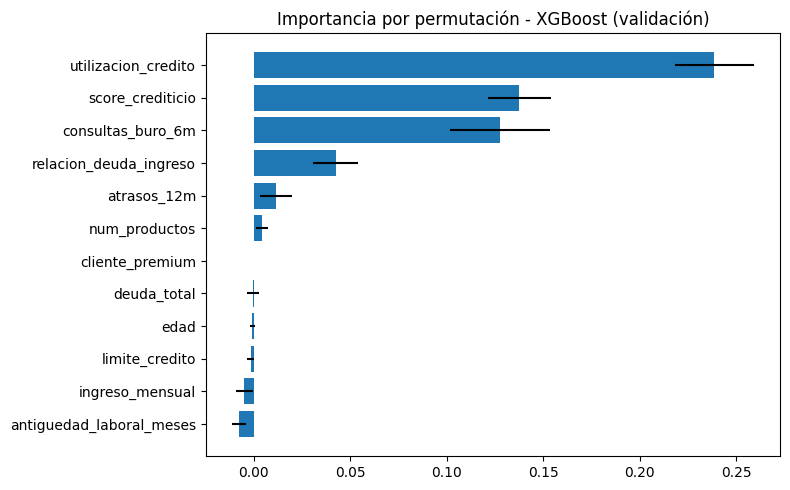

In [28]:
# C7) Importancia de variables del mejor modelo.
# Importancia por permutación en VALIDACIÓN: cuánto empeora la PR-AUC al revolver cada variable.
# Es más confiable que feature_importances_, que favorece variables continuas con muchos cortes posibles.
perm = permutation_importance(mejor_m, Xva, yva, scoring='average_precision',
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({'Variable': Xva.columns, 'Importancia (caída PR-AUC)': perm.importances_mean,
                    'std': perm.importances_std}).sort_values('Importancia (caída PR-AUC)', ascending=False)
print(imp.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(imp['Variable'][::-1], imp['Importancia (caída PR-AUC)'][::-1], xerr=imp['std'][::-1])
plt.title(f'Importancia por permutación - {mejor_nombre} (validación)'); plt.tight_layout(); plt.show()

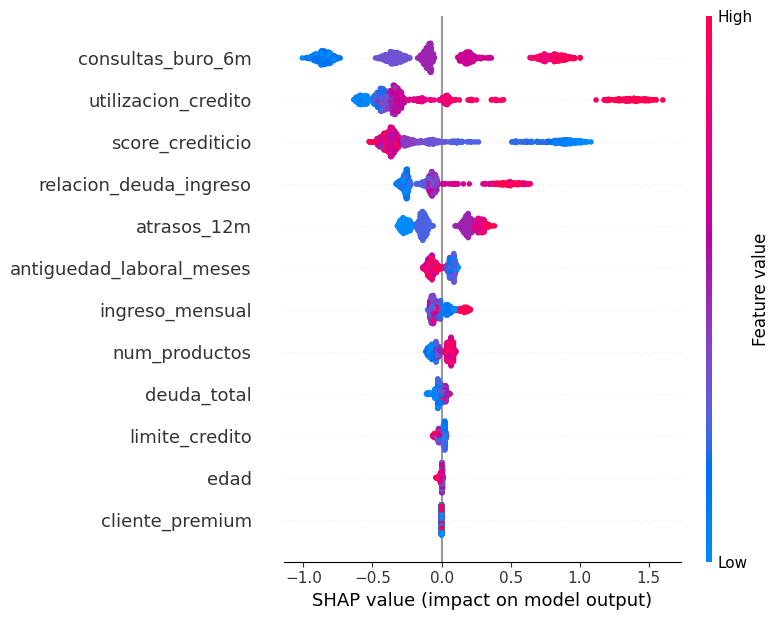

In [29]:
# Complemento con SHAP (dirección del efecto de cada variable). Se calcula sobre clientes REALES de validación.
try:
    explainer_c = shap.TreeExplainer(mejor_m)
    sv = explainer_c.shap_values(Xva)
    if isinstance(sv, list):          # algunos modelos devuelven una lista por clase
        sv = sv[1]
    elif np.ndim(sv) == 3:            # (n, variables, clases)
        sv = sv[:, :, 1]
    shap.summary_plot(sv, Xva)
except Exception as e:
    print("SHAP no disponible para este modelo/versión:", e)

In [30]:
# C7b) Dirección del efecto de los 4 factores principales (solo con datos de ENTRENAMIENTO):
# tasa de incumplimiento por quintil de cada variable.
top4 = imp['Variable'].head(4).tolist()
for v in top4:
    q = pd.qcut(Xtr[v], 5, duplicates='drop')
    tasa = ytr.groupby(q, observed=True).mean() * 100
    print(f"\n{v}: tasa de incumplimiento por quintil (de menor a mayor valor)")
    print("  " + " | ".join(f"{t:.1f}%" for t in tasa.values))


utilizacion_credito: tasa de incumplimiento por quintil (de menor a mayor valor)
  4.8% | 7.0% | 9.7% | 8.8% | 28.3%

score_crediticio: tasa de incumplimiento por quintil (de menor a mayor valor)
  22.3% | 10.5% | 8.3% | 9.3% | 8.2%

consultas_buro_6m: tasa de incumplimiento por quintil (de menor a mayor valor)
  4.7% | 8.8% | 10.6% | 14.4% | 22.5%

relacion_deuda_ingreso: tasa de incumplimiento por quintil (de menor a mayor valor)
  5.7% | 5.5% | 11.2% | 12.8% | 23.5%


### **Interpretabilidad desde el negocio**

Los cuatro factores que encabezan la importancia por permutación del mejor modelo están, junto con `deuda_total`, entre las variables con mayor correlación con el incumplimiento. La celda C7b confirma la dirección de cada efecto con la tasa de incumplimiento por quintil (solo en entrenamiento):

* **`utilizacion_credito`:** es el factor más fuerte. El 20% de clientes que más usa sus líneas incumple 28.3%, contra 4.8% del quintil que menos las usa. Un cliente con las tarjetas al tope ya no tiene margen para absorber un imprevisto, y suele ser la primera señal de estrés financiero.
* **`score_crediticio`:** el quintil con peor calificación incumple 22.3%, contra 8% a 10.5% en el resto. Resume el historial acumulado; el efecto se concentra en el extremo bajo, y arriba de cierto nivel el score casi deja de diferenciar.
* **`consultas_buro_6m`:** pasa de 4.7% a 22.5% de incumplimiento entre el quintil más bajo y el más alto. Muchas consultas recientes significan que el cliente está buscando crédito en varios lugares, típico de quien necesita liquidez con urgencia.
* **`relacion_deuda_ingreso`:** el quintil más endeudado frente a su ingreso incumple 23.5%, contra 5.7%. Mide la capacidad real de pago, más allá del ingreso o la deuda por separado (por eso `deuda_total` e `ingreso_mensual` pesan poco: su información ya está en esta razón; ver E10).

En términos de negocio, el perfil de riesgo es claro y tiene sentido: un cliente muy apalancado, con las líneas al tope y buscando más crédito. Esto le da al comité de riesgos argumentos para explicar un rechazo, algo importante en crédito al consumo. Variables como `edad` o `cliente_premium` casi no aportan; en el caso de la edad conviene revisar con Cumplimiento si su uso está permitido.

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

### +++++++++++ Inicia sección de Conclusiones Particulares ++++++++++++++++

**Reporte de auditoría para el CEO de CrediNova**

**Para:** CEO de CrediNova · **De:** Ciencia de Datos (auditoría) · **Asunto:** ¿Se puede desplegar el modelo de riesgo?

**Respuesta corta: no como está.** El 100% de aciertos que reporta la propuesta no es real. El modelo usaba el atraso de los 30 días *posteriores* a la evaluación, un dato que no tendremos al momento de aprobar un crédito; con esa sola variable, una regla simple acierta todo. Además, el 44% de los clientes con los que se evaluó eran registros inventados por la técnica de balanceo. En producción el desempeño habría sido muy inferior al prometido y las pérdidas por incumplimiento nos habrían tomado por sorpresa.

**Lo que sí funciona.** Corregimos esos errores y reentrenamos con datos reales. El mejor modelo fue **XGBoost**. En utilidad quedó prácticamente empatado con Random Forest (menos de 2% de diferencia), pero ordena mejor el riesgo, no muestra sobreentrenamiento y es más sencillo, con árboles de solo dos niveles. En 1,000 clientes que el modelo nunca había visto, la utilidad por cada 10,000 solicitudes sería:

* **Aprobar a todos, sin modelo:** \$298,000.
* **Modelo con el umbral estándar (0.50):** \$366,000. Se gana poco, porque casi nadie supera ese nivel de riesgo y se aprueba prácticamente a todos.
* **Modelo con el umbral ajustado al negocio (0.15):** **\$532,000**, es decir, **\$234,000 más que sin modelo (+79%)**. Con 95% de confianza, la ganancia adicional está entre \$146,000 y \$323,000.

**El costo de esa decisión.** Con ese umbral rechazaríamos al 24% de los solicitantes. Detectaríamos 79 de cada 117 morosos (68%), pero también rechazaríamos a 161 de cada 883 buenos clientes (18%). La lógica es simple: un moroso nos cuesta \$500 y un buen cliente nos deja \$100, así que conviene rechazar a quien tenga más de ~17% de probabilidad de incumplir.

**Qué mira el modelo.** Los cuatro factores que más pesan son:
1. Qué tan cerca del tope trae el cliente sus líneas de crédito. Es el más fuerte: el 20% que más las usa incumple 28%, contra 5% de los que menos las usan.
2. Su calificación crediticia histórica.
3. Cuántas veces ha buscado crédito en otras instituciones en los últimos seis meses.
4. Cuánto debe en relación con lo que gana.

Es un perfil fácil de explicar: un cliente muy endeudado, con las tarjetas al tope y buscando más crédito.

**Recomendaciones:**
1. **No autorizar** el despliegue de la versión original.
2. **Piloto de 3 meses** con el modelo corregido en paralelo al proceso actual, sin tomar decisiones con él, para medir su utilidad real.
3. **Validar con las áreas de origen** que cada dato se toma a la fecha de evaluación, en especial el score y el segmento premium.
4. **Acordar con el área comercial** el nivel de rechazo aceptable. El 24% puede ser alto para las metas de colocación; una opción es revisar manualmente los casos cercanos al umbral.
5. **Tratar el umbral como palanca de negocio** y revisarlo cuando cambien la ganancia o la pérdida por crédito.
6. **Monitorear cada mes** la tasa de incumplimiento de los aprobados y reentrenar si se desvía.
7. **Revisar con Cumplimiento** el uso de la edad como variable, por posibles restricciones regulatorias en crédito.

Entre los tres modelos evaluados, la diferencia de utilidad en validación fue de apenas \$13,000 por cada 10,000 solicitudes. La decisión que más valor genera no es el algoritmo, sino corregir los datos y fijar bien el umbral.

### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

La lección de esta auditoría es que un resultado demasiado bueno es, antes que nada, una señal de alarma. El 100% de exactitud no venía de un gran modelo, sino de una variable del futuro y de un conjunto de prueba lleno de clientes inventados. Una vez corregido, el modelo realista es mucho más modesto (ROC-AUC alrededor de 0.8), pero aun así vale dinero: casi duplica la utilidad de aprobar a todos, siempre que el umbral se fije con la lógica del negocio y no en 0.5.

Me llevo también que la diferencia entre algoritmos fue pequeña comparada con la diferencia entre hacer bien o mal el proceso: partir primero, validar sin tocar la prueba y elegir el umbral con costos reales. Esto conecta directamente con mi experiencia en automatización para la industria automotriz. Usar `dias_max_atraso_30d_despues` es como predecir si una pieza saldrá defectuosa usando el resultado de la prueba de fin de línea: en el análisis parece perfecto, pero en la estación donde hay que decidir ese dato todavía no existe.

**Uso de IA generativa:**

* **Herramientas:** Claude (Anthropic), a través de claude.ai, y GitHub Copilot (Microsoft).

* **Dónde fue de mayor provecho:**
  * Para recorrer el cuaderno de forma sistemática y detectar errores encadenados: la fuga explicaba el 100%, SMOTE contaminaba la prueba y eso a su vez inflaba la utilidad.
  * Para escribir rápido el pipeline corregido, las pruebas de evidencia y los intervalos por bootstrap.
* **Limitaciones que observé:**
  * El entorno del LLM no tenía XGBoost ni SHAP instalados, así que una parte del código solo se pudo verificar al correrlo en Colab. Las cifras de XGBoost las confirmé con mi propia ejecución antes de redactar la comparación.
  * En una actividad anterior, el asistente integrado de Colab propuso una corrección que hacía correr el código pero con una estrategia equivocada. Un LLM tiende a resolver el error visible, no a cuestionar el planteamiento.
* **Dónde fue clave mi intervención:**
  * Confirmar con la *Tabla de Variables* que la variable era posterior a la evaluación.
  * Decidir que el umbral es un parámetro de negocio y no técnico.
  * Señalar riesgos que no están en los datos, como el momento en que se extrae cada variable o el posible uso regulatorio de la edad.
  * Leer los resultados con criterio de negocio antes de recomendar el despliegue. La regla automática elegía Random Forest por una diferencia equivalente a un solo cliente; decidir que eso era ruido y cambiar el criterio de desempate fue un juicio propio, no algo que el código resolviera solo.

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **Referencias**

Elkan, C. (2001). The foundations of cost-sensitive learning. En *Proceedings of the 17th International Joint Conference on Artificial Intelligence* (pp. 973–978). https://www.ijcai.org/Proceedings/01/IJCAI-2001-k.pdf

Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3a ed., caps. 2, 3, 6 y 7). O'Reilly Media.

Kaufman, S., Rosset, S., Perlich, C., y Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579

Lemaître, G., Nogueira, F., y Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5. https://jmlr.org/papers/v18/16-365.html

Lundberg, S. M., y Lee, S.-I. (2017). A unified approach to interpreting model predictions. En *Advances in Neural Information Processing Systems 30*. https://arxiv.org/abs/1705.07874

Saito, T., y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

scikit-learn developers. (s.f.). *Permutation feature importance* y *Tuning the decision threshold for class prediction*. Scikit-learn. https://scikit-learn.org/stable/modules/permutation_importance.html

---

**Declaración de uso de IA**

Anthropic. (2026). Claude [modelo de lenguaje grande], utilizado para estructurar la auditoría, redactar el pipeline corregido y revisar la consistencia entre el texto y los resultados. https://claude.ai/

Microsoft. (2026). GitHub Copilot [asistente de programación], utilizado para corrección de código y para acomodar texto junto al mismo. https://github.com/features/copilot

---

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**